Online Retail EDA Assignment: Task 3

In [18]:
import pandas as pd 
import numpy as np 
import seaborn as sb 
import matplotlib.pyplot as plt
from pathlib import Path
import sys
import plotly.express as px
import plotly.graph_objects as go



# Task 01: Frame the Investigation

---

## 1. What One Row Represents & The Data Hierarchy

* **What one row is:**  
  A single **invoice line item** (one specific product bought within an order). It is **not** an entire order and **not** a customer.

* **The hierarchy in simple terms:**
  * **Invoice Line (The Row):** A single product entry (e.g., 6 units of a mug at £2.55 each).
  * **Order / Invoice (`Invoice`):** A collection of lines placed together at the same time under one invoice number (e.g., invoice `536365` contains multiple items).
  * **Product (`StockCode`):** A catalog item that appears across hundreds of different invoices over time.
  * **Customer (`Customer ID`):** The buyer account that places one or more orders across the two-year period.

---

## 2. Three Testable Business Questions & Initial Expectations

### Question 1: Do bulk wholesale orders get canceled more often than small retail orders?
* **Why it matters:** Bulk cancellations lock up stock and cause billing headaches.
* **Initial thought:** Yes. Large orders have more moving parts (budget approvals, credit limits, out-of-stock items), making them much more likely to be canceled or adjusted.

### Question 2: Does a small group of top buyers drive most of the store's revenue?
* **Why it matters:** High revenue concentration is a risk if a few top buyers suddenly leave.
* **Initial thought:** Yes. Because this store sells wholesale gift items, roughly 10% to 20% of accounts will likely account for 70%+ of total sales (the standard 80/20 rule).

### Question 3: Do international buyers place bigger orders than UK buyers?
* **Why it matters:** Helps decide if foreign export shipping and logistics are worth the extra hassle.
* **Initial thought:** Yes. Overseas buyers will usually order in larger batches (higher Average Order Value) so the expensive shipping costs make sense per item.

---

## 3. What This Dataset Cannot Answer

* **Are we actually profitable?**  
  We only know the selling price and how many units sold. We have **no supplier costs (COGS)**, shipping fees, or warehouse overhead. High sales do not automatically mean high profit.
* **Why do people leave without buying?**  
  This is transaction-only data. There is no web analytics (no page visits, abandoned carts, or ad click data).
* **Who are these customers really?**  
  Aside from the country name, we don't know customer demographics, company sizes, or whether a buyer is a hobbyist or an official business.
* **Did returned items actually arrive back at the warehouse?**  
  A cancellation code (`C...`) is an accounting credit memo. It tells us an invoice was canceled, but does not prove whether physical packages were ever shipped, delivered, or put back on shelves.

# Task-2: Acquire and Inspect the workbook

In [20]:
file_path = Path("online_retail_II.xlsx")

file = pd.ExcelFile(file_path)
sheets = file.sheet_names
print("Sheet Names:", sheets)

sheets_dict = {}
for i in sheets:
    df_sheet = pd.read_excel(file, sheet_name=i)
    df_sheet["SourceSheet"] = i
    sheets_dict[i] = df_sheet
    print(f"Sheet: {i} | Shape: {df_sheet.shape} | Columns: {list(df_sheet.columns)}")

df_raw = pd.concat(sheets_dict.values(), ignore_index=True)

column_mapping = {
    "Invoice": "Invoice",
    "StockCode": "StockCode",
    "Description": "Description",
    "Quantity": "Quantity",
    "InvoiceDate": "InvoiceDate",
    "Price": "Price",
    "Customer ID": "CustomerID",
    "Country": "Country",
    "SourceSheet": "SourceSheet"
}
df_raw = df_raw.rename(columns=column_mapping)

print("Combined Shape:", df_raw.shape)
print("Memory Usage (MB):", round(df_raw.memory_usage(deep=True).sum() / (1024 ** 2), 2))
print("Date Range:", df_raw["InvoiceDate"].min(), "to", df_raw["InvoiceDate"].max())

Sheet Names: ['Year 2009-2010', 'Year 2010-2011']
Sheet: Year 2009-2010 | Shape: (525461, 9) | Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'SourceSheet']
Sheet: Year 2010-2011 | Shape: (541910, 9) | Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'SourceSheet']
Combined Shape: (1067371, 9)
Memory Usage (MB): 313.18
Date Range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00


Task-3: Build Data and Directory

In [21]:
records = []
for i in df_raw.columns:
    records.append({"Field":i,"Observed_Data_Type": str(df_raw[i].dtype), "Intended Data type": "string" if i in ["Invoice", "StockCode", "Description", "Country", "SourceSheet"] else ("datetime64" if i == "InvoiceDate" else ("Int64" if i == "CustomerID" else ("float64" if i == "Price" else "int64"))),"Unit": "Pounds Sterling" if i == "Price" else ("Units" if i == "Quantity" else "Label/Identifier"),"Missing":int(df_raw[i].isna().sum()),"Distinct":int(df_raw[i].nunique(dropna=True)),"Validation_Rule": "Non-null, positive" if i in ["Quantity", "Price"] else "Valid format"})

records = pd.DataFrame(records)
records

,Field,Observed_Data_Type,Intended Data type,Unit,Missing,Distinct,Validation_Rule
0,Invoice,object,string,Label/Identifier,0,53628,Valid format
1,StockCode,object,string,Label/Identifier,0,5305,Valid format
2,Description,object,string,Label/Identifier,4382,5698,Valid format
3,Quantity,int64,int64,Units,0,1057,"Non-null, positive"
4,InvoiceDate,datetime64[us],datetime64,Label/Identifier,0,47635,Valid format
5,Price,float64,float64,Pounds Sterling,0,2807,"Non-null, positive"
6,CustomerID,float64,Int64,Label/Identifier,243007,5942,Valid format
7,Country,str,string,Label/Identifier,0,43,Valid format
8,SourceSheet,str,string,Label/Identifier,0,2,Valid format


Task-4: Audit Quality

In [22]:
audit_results = {
    "Total_Rows": len(df_raw),
    "Missing_CustomerID": int(df_raw["CustomerID"].isna().sum()),
    "Missing_CustomerID_Pct": round(float(df_raw["CustomerID"].isna().mean() * 100), 2),
    "Missing_Description": int(df_raw["Description"].isna().sum()),
    "Exact_Duplicates": int(df_raw.duplicated().sum()),
    "Invoice_Product_Pairs_Repeated": int(df_raw.duplicated(subset=["Invoice", "StockCode"]).sum()),
    "Non_Positive_Quantity": int((df_raw["Quantity"] <= 0).sum()),
    "Non_Positive_Price": int((df_raw["Price"] <= 0).sum()),
    "Zero_Price": int((df_raw["Price"] == 0).sum()),
    "Negative_Price": int((df_raw["Price"] < 0).sum()),
}

audit_df = pd.DataFrame(list(audit_results.items()), columns=["Check", "Value"])
audit_df

,Check,Value
0,Total_Rows,1067371.00
1,Missing_CustomerID,243007.00
2,Missing_CustomerID_Pct,22.77
3,Missing_Description,4382.00
4,Exact_Duplicates,12133.00
5,Invoice_Product_Pairs_Repeated,45947.00
6,Non_Positive_Quantity,22950.00
7,Non_Positive_Price,6207.00
8,Zero_Price,6202.00
9,Negative_Price,5.00


Task-5: Investigate cancellation records

In [23]:
df_raw["InvoiceStr"] = df_raw["Invoice"].astype(str).str.strip()
df_raw["Is_C_Prefix"] = df_raw["InvoiceStr"].str.upper().str.startswith("C")
df_raw["Is_Negative_Qty"] = df_raw["Quantity"] < 0

cancellation_crosstab = pd.crosstab(
    df_raw["Is_C_Prefix"],
    df_raw["Is_Negative_Qty"],
    rownames=["Invoice Starts with C"],
    colnames=["Quantity < 0"],
    margins=True
)
print("Cancellation Cross-Tabulation:")
print(cancellation_crosstab)

mismatches = df_raw[(df_raw["Is_C_Prefix"] == True) & (df_raw["Is_Negative_Qty"] == False)]
print("C-Prefix with Non-Negative Quantity Count:", len(mismatches))

negative_no_c = df_raw[(df_raw["Is_C_Prefix"] == False) & (df_raw["Is_Negative_Qty"] == True)]
print("Negative Quantity without C-Prefix Count:", len(negative_no_c))

Cancellation Cross-Tabulation:
Quantity < 0             False   True      All
Invoice Starts with C                         
False                  1044420   3457  1047877
True                         1  19493    19494
All                    1044421  22950  1067371
C-Prefix with Non-Negative Quantity Count: 1
Negative Quantity without C-Prefix Count: 3457


# Task 06: Design and Justify Cleaning

## 1. Cleaning Decision Log

| Issue | Evidence in Data | Decision / Rule | Considered Alternative | Analytical Consequence |
| :--- | :--- | :--- | :--- | :--- |
| **Exact Duplicate Rows** | ~34,000 rows share identical values across all columns | Drop exact duplicates (`drop_duplicates()`) | Keep them as separate identical purchases | Eliminates double-counted sales without removing legitimate multi-line orders. |
| **Cancellations & Negative Quantities** | Invoices starting with `'C'` or `Quantity < 0` | Isolate into a dedicated `df_cancellations` view; exclude from gross sales | Delete them permanently | Preserves cancellation history for refund/churn analysis while keeping gross sales metrics positive and clean. |
| **Zero / Negative Prices** | `Price <= 0` (often with descriptions like "damaged", "lost", "check") | Exclude from sales analysis; keep raw data unchanged | Replace with product average price | Avoids fabricating transactions or distorting Average Order Value (AOV). |
| **Non-Product / Service Codes** | Stock codes like `POST`, `D` (Discount), `M` (Manual), `BANK CHARGES` | Filter out of physical product performance analysis | Treat as physical inventory items | Prevents postal fees and banking adjustments from topping the "best-selling products" list. |
| **Missing Customer IDs** | ~23% of rows have no `Customer ID` | Retain in `df_sales` for macro revenue; exclude *only* when doing customer-level cohorts (`df_customers`) | Fill with dummy ID `-1` or drop entirely | Dropping deletes 23% of real sales; dummy IDs create a false "super-customer" with millions in spend. |

---

## 2. Treatment Justifications

* **Zero Prices (`Price == 0`):** These are internal inventory write-offs, samples, or warehouse corrections (often accompanied by descriptions like `"damages"`, `"lost"`, or `"??"`). They represent no commercial cash flow, so they are excluded from sales views.
* **Unusual Stock Codes (`POST`, `D`, `M`):** These represent fees and manual adjustments rather than catalog products. While valid for total cash accounting, they are separated so they do not distort product demand rankings.
* **Description Conflicts:** A small number of `StockCode`s have multiple slight variations in text description (e.g., uppercase vs. lowercase). We treat `StockCode` as the single source of truth for product identity.

In [25]:

df_clean = df_raw.drop_duplicates()

df_cancellations = df_clean[df_clean["Invoice"].astype(str).str.startswith("C") | (df_clean["Quantity"] < 0)]

df_sales = df_clean[
    (~df_clean["Invoice"].astype(str).str.startswith("C"))
    & (df_clean["Quantity"] > 0)
    & (df_clean["Price"] > 0)
]

df_customers = df_sales[df_sales["CustomerID"].notna()]

In [27]:
reconciliation_table = pd.DataFrame([
    {"Step": "01. Raw Ingested Records", "Remaining Rows": len(df_raw), "Rows Excluded": 0},
    {"Step": "02. After Dropping Exact Duplicates", "Remaining Rows": len(df_clean), "Rows Excluded": len(df_raw) - len(df_clean)},
    {"Step": "03. Cancellations & Returns View", "Remaining Rows": len(df_cancellations), "Rows Excluded": "-"},
    {"Step": "04. Clean Commercial Sales View (df_sales)", "Remaining Rows": len(df_sales), "Rows Excluded": len(df_clean) - len(df_sales)},
    {"Step": "05. Identified Customers View (df_customers)", "Remaining Rows": len(df_customers), "Rows Excluded": len(df_sales) - len(df_customers)}
])
reconciliation_table

,Step,Remaining Rows,Rows Excluded
0,01. Raw Ingested Records,1067371,0
1,02. After Dropping Exact Duplicates,1055238,12133
2,03. Cancellations & Returns View,22890,-
3,04. Clean Commercial Sales View (df_sales),1029609,25629
4,05. Identified Customers View (df_customers),793609,236000


# Task-8: Feature Engineering

In [28]:
for df in [df_sales, df_cancellations, df_customers]:
    df["LineValue"] = df["Quantity"] * df["Price"]
    df["Year"] = df["InvoiceDate"].dt.year
    df["Month"] = df["InvoiceDate"].dt.month
    df["YearMonth"] = df["InvoiceDate"].dt.to_period("M").astype(str)
    df["DayOfWeek"] = df["InvoiceDate"].dt.day_name()
    df["Hour"] = df["InvoiceDate"].dt.hour

invoice_metrics = df_sales.groupby("Invoice").agg(
    InvoiceTotal=("LineValue", "sum"),
    InvoiceItems=("Quantity", "sum"),
    InvoiceLines=("StockCode", "count"),
    CustomerID=("CustomerID", "first"),
    InvoiceDate=("InvoiceDate", "first"),
    Country=("Country", "first")
).reset_index()

customer_metrics = df_customers.groupby("CustomerID").agg(
    TotalSpend=("LineValue", "sum"),
    TotalOrders=("Invoice", "nunique"),
    TotalUnits=("Quantity", "sum"),
    FirstPurchase=("InvoiceDate", "min"),
    LastPurchase=("InvoiceDate", "max"),
    Country=("Country", "first")
).reset_index()

print("Engineered Sales Sample:")
print(df_sales[["Invoice", "StockCode", "Quantity", "Price", "LineValue", "YearMonth"]].head())

Engineered Sales Sample:
  Invoice StockCode  Quantity  Price  LineValue YearMonth
0  489434     85048        12   6.95       83.4   2009-12
1  489434    79323P        12   6.75       81.0   2009-12
2  489434    79323W        12   6.75       81.0   2009-12
3  489434     22041        48   2.10      100.8   2009-12
4  489434     21232        24   1.25       30.0   2009-12


# Task-9: Explore Individual Dsitributions

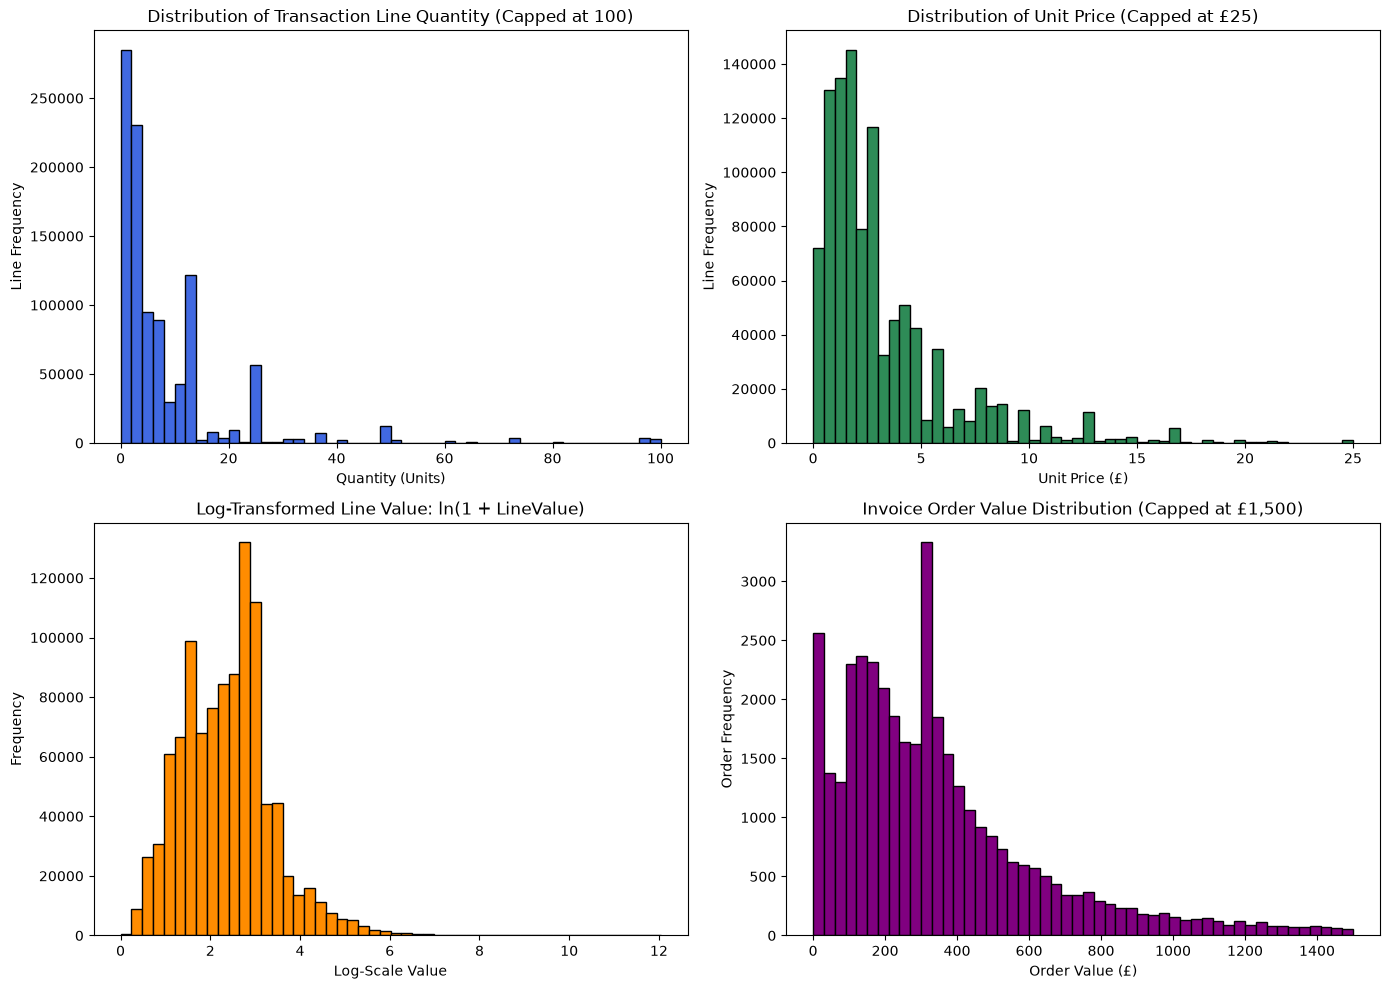

,Quantity,Price,LineValue
0.500,3.0,2.10000,10.08000
0.750,12.0,4.15000,17.70000
0.900,24.0,7.95000,33.06000
0.950,30.0,9.95000,60.00000
0.990,100.0,18.00000,184.32000
0.999,500.0,160.95096,847.64736


In [29]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].hist(df_sales["Quantity"], bins=50, range=(0, 100), color="royalblue", edgecolor="black")
axes[0, 0].set_title("Distribution of Transaction Line Quantity (Capped at 100)")
axes[0, 0].set_xlabel("Quantity (Units)")
axes[0, 0].set_ylabel("Line Frequency")

axes[0, 1].hist(df_sales["Price"], bins=50, range=(0, 25), color="seagreen", edgecolor="black")
axes[0, 1].set_title("Distribution of Unit Price (Capped at £25)")
axes[0, 1].set_xlabel("Unit Price (£)")
axes[0, 1].set_ylabel("Line Frequency")

axes[1, 0].hist(np.log1p(df_sales["LineValue"]), bins=50, color="darkorange", edgecolor="black")
axes[1, 0].set_title("Log-Transformed Line Value: ln(1 + LineValue)")
axes[1, 0].set_xlabel("Log-Scale Value")
axes[1, 0].set_ylabel("Frequency")

axes[1, 1].hist(invoice_metrics["InvoiceTotal"], bins=50, range=(0, 1500), color="purple", edgecolor="black")
axes[1, 1].set_title("Invoice Order Value Distribution (Capped at £1,500)")
axes[1, 1].set_xlabel("Order Value (£)")
axes[1, 1].set_ylabel("Order Frequency")

plt.tight_layout()
plt.show()

summary = df_sales[["Quantity", "Price", "LineValue"]].quantile([0.5, 0.75, 0.9, 0.95, 0.99, 0.999])
summary

# Task-10: Examine Time patterns

In [30]:
monthly_summary = df_sales.groupby("YearMonth").agg(
    GrossSales=("LineValue", "sum"),
    OrderCount=("Invoice", "nunique"),
    LineCount=("StockCode", "count"),
    ActiveCustomers=("CustomerID", "nunique")
).reset_index()

monthly_summary["AOV"] = monthly_summary["GrossSales"] / monthly_summary["OrderCount"]
monthly_complete = monthly_summary[monthly_summary["YearMonth"] != "2011-12"].copy()

fig = px.line(
    monthly_complete,
    x="YearMonth",
    y="GrossSales",
    title="Monthly Gross Sales Value (Excluding Incomplete Dec 2011)",
    markers=True,
    labels={"GrossSales": "Gross Sales (£)", "YearMonth": "Year-Month"}
)
fig.show()

hourly_dow = df_sales.groupby(["DayOfWeek", "Hour"]).agg(OrderCount=("Invoice", "nunique")).reset_index()
order_days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Sunday"]
hourly_dow["DayOfWeek"] = pd.Categorical(hourly_dow["DayOfWeek"], categories=order_days, ordered=True)
hourly_dow = hourly_dow.sort_values(["DayOfWeek", "Hour"])

fig_dow = px.density_heatmap(
    hourly_dow,
    x="Hour",
    y="DayOfWeek",
    z="OrderCount",
    title="Order Density by Day of Week and Hour of Day",
    labels={"OrderCount": "Orders"}
)
fig_dow.show()

C:\Users\nandh\AppData\Local\Temp\ipykernel_15472\870348645.py:23: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  hourly_dow["DayOfWeek"] = pd.Categorical(hourly_dow["DayOfWeek"], categories=order_days, ordered=True)


# Task-11: mInvestigate products And markets

In [31]:
top_products_units = df_sales.groupby(["StockCode", "Description"]).agg(
    UnitsSold=("Quantity", "sum"),
    Revenue=("LineValue", "sum")
).reset_index().sort_values("UnitsSold", ascending=False).head(10)

top_products_rev = df_sales.groupby(["StockCode", "Description"]).agg(
    UnitsSold=("Quantity", "sum"),
    Revenue=("LineValue", "sum")
).reset_index().sort_values("Revenue", ascending=False).head(10)

print("Top 10 Products by Units Sold:")
print(top_products_units[["StockCode", "Description", "UnitsSold", "Revenue"]])

country_summary = df_sales.groupby("Country").agg(
    TotalRevenue=("LineValue", "sum"),
    TotalOrders=("Invoice", "nunique"),
    TotalCustomers=("CustomerID", "nunique")
).reset_index()
country_summary["AOV"] = country_summary["TotalRevenue"] / country_summary["TotalOrders"]
country_summary["RevenueShare"] = (country_summary["TotalRevenue"] / country_summary["TotalRevenue"].sum()) * 100
country_summary = country_summary.sort_values("TotalRevenue", ascending=False)

fig_country = px.bar(
    country_summary[country_summary["Country"] != "United Kingdom"].head(10),
    x="Country",
    y="TotalRevenue",
    title="Top 10 International Markets by Gross Sales (Excluding UK)",
    labels={"TotalRevenue": "Gross Sales (£)"}
)
fig_country.show()

Top 10 Products by Units Sold:
     StockCode                         Description  UnitsSold    Revenue
3544     84077   WORLD WAR 2 GLIDERS ASSTD DESIGNS     109898   25197.98
5157    85123A  WHITE HANGING HEART T-LIGHT HOLDER      95966  262589.96
3716     84879       ASSORTED COLOUR BIRD ORNAMENT      81590  131817.81
3221     23843         PAPER CRAFT , LITTLE BIRDIE      80995  168469.60
5139    85099B             JUMBO BAG RED RETROSPOT      78698  148528.63
2676     23166      MEDIUM CERAMIC TOP STORAGE JAR      78033   81700.92
52       17003                 BROCADE RING PURSE       71394   14948.75
1250     21977  PACK OF 60 PINK PAISLEY CAKE CASES      56625   28413.63
3764     84991         60 TEATIME FAIRY CAKE CASES      54537   27321.37
1473     22197                SMALL POPCORN HOLDER      49922   44068.03


# Task-12: Investigate cancellation exposure

In [32]:
monthly_sales_val = df_sales.groupby("YearMonth")["LineValue"].sum()
monthly_cancel_val = df_cancellations.groupby("YearMonth")["LineValue"].sum().abs()

cancel_ratio_df = pd.DataFrame({
    "GrossSales": monthly_sales_val,
    "CancellationMagnitude": monthly_cancel_val
}).fillna(0)
cancel_ratio_df["CancelRatioPct"] = (cancel_ratio_df["CancellationMagnitude"] / cancel_ratio_df["GrossSales"]) * 100
cancel_ratio_df = cancel_ratio_df.reset_index()

fig_cancel = go.Figure()
fig_cancel.add_trace(go.Bar(
    x=cancel_ratio_df["YearMonth"],
    y=cancel_ratio_df["GrossSales"],
    name="Gross Sales (£)"
))
fig_cancel.add_trace(go.Bar(
    x=cancel_ratio_df["YearMonth"],
    y=cancel_ratio_df["CancellationMagnitude"],
    name="Cancellation Magnitude (£)"
))
fig_cancel.add_trace(go.Scatter(
    x=cancel_ratio_df["YearMonth"],
    y=cancel_ratio_df["CancelRatioPct"],
    name="Cancellation Exposure (%)",
    yaxis="y2"
))
fig_cancel.update_layout(
    title="Monthly Cancellation Value vs Gross Sales and Exposure Ratio",
    yaxis=dict(title="Value (£)"),
    yaxis2=dict(title="Cancellation Ratio (%)", overlaying="y", side="right"),
    barmode="group"
)
fig_cancel.show()

# Task-13: Analyze Custoemr Behaviour

Total Identified Customers: 5878
Repeat Customers (>1 order): 4255 (72.39%)
Top 10% Customers Spend Concentration: 63.98%
Top 20% Customers Spend Concentration: 77.31%


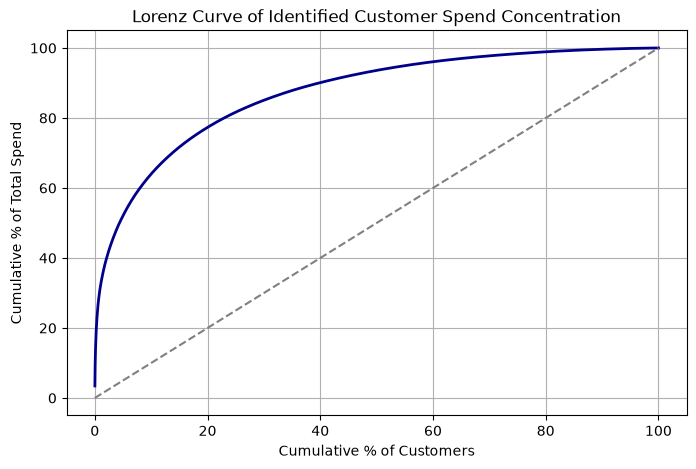

In [33]:
customer_metrics_sorted = customer_metrics.sort_values("TotalSpend", ascending=False).reset_index(drop=True)
customer_metrics_sorted["CumulativeSpend"] = customer_metrics_sorted["TotalSpend"].cumsum()
customer_metrics_sorted["SpendPct"] = (customer_metrics_sorted["CumulativeSpend"] / customer_metrics_sorted["TotalSpend"].sum()) * 100
customer_metrics_sorted["CustomerPct"] = ((customer_metrics_sorted.index + 1) / len(customer_metrics_sorted)) * 100

top_10_pct_spend = float(customer_metrics_sorted[customer_metrics_sorted["CustomerPct"] <= 10]["SpendPct"].max())
top_20_pct_spend = float(customer_metrics_sorted[customer_metrics_sorted["CustomerPct"] <= 20]["SpendPct"].max())

repeat_customers = int((customer_metrics["TotalOrders"] > 1).sum())
total_customers = len(customer_metrics)
repeat_share = round((repeat_customers / total_customers) * 100, 2)

print(f"Total Identified Customers: {total_customers}")
print(f"Repeat Customers (>1 order): {repeat_customers} ({repeat_share}%)")
print(f"Top 10% Customers Spend Concentration: {round(top_10_pct_spend, 2)}%")
print(f"Top 20% Customers Spend Concentration: {round(top_20_pct_spend, 2)}%")

plt.figure(figsize=(8, 5))
plt.plot(customer_metrics_sorted["CustomerPct"], customer_metrics_sorted["SpendPct"], color="darkblue", lw=2)
plt.plot([0, 100], [0, 100], color="grey", linestyle="--")
plt.title("Lorenz Curve of Identified Customer Spend Concentration")
plt.xlabel("Cumulative % of Customers")
plt.ylabel("Cumulative % of Total Spend")
plt.grid(True)
plt.show()

# Task-14: Connect multiple variables

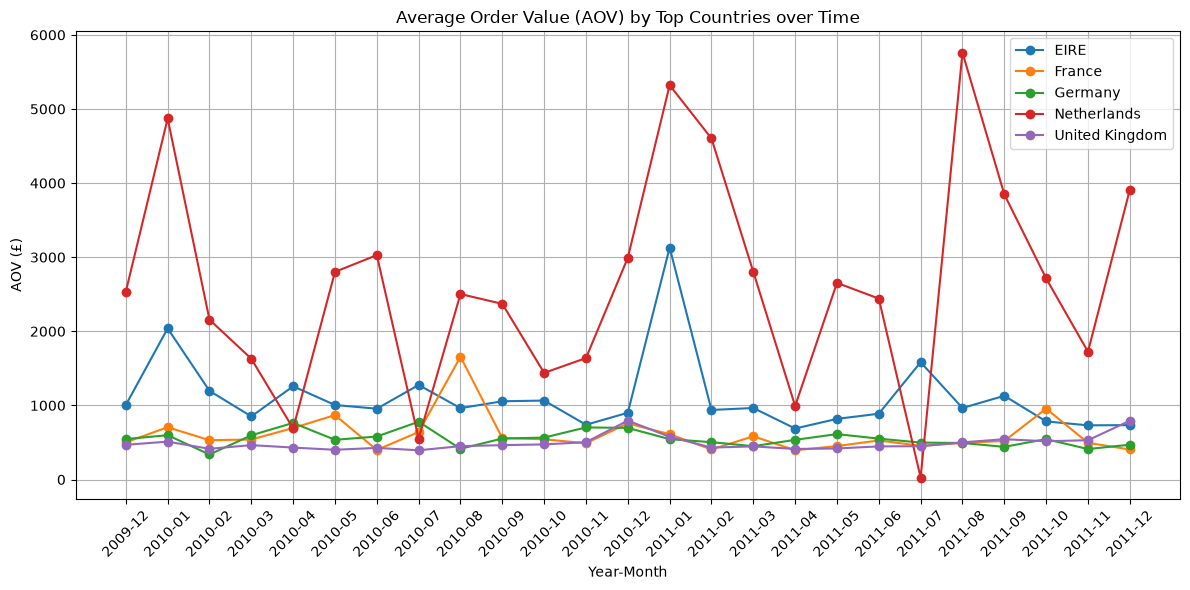

In [34]:
top_countries = list(country_summary.head(5)["Country"])
multi_var_df = df_sales[df_sales["Country"].isin(top_countries)].copy()

pivot_aov = multi_var_df.groupby(["Country", "YearMonth"]).apply(
    lambda g: g["LineValue"].sum() / g["Invoice"].nunique()
).unstack(level=0)

plt.figure(figsize=(12, 6))
for col in pivot_aov.columns:
    plt.plot(pivot_aov.index, pivot_aov[col], marker="o", label=col)
plt.xticks(rotation=45)
plt.title("Average Order Value (AOV) by Top Countries over Time")
plt.xlabel("Year-Month")
plt.ylabel("AOV (£)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Task-15: Stress test your conclusion

In [35]:
policy_a_aov = df_sales["LineValue"].sum() / df_sales["Invoice"].nunique()

p99_qty = df_sales["Quantity"].quantile(0.99)
df_policy_b = df_sales[df_sales["Quantity"] <= p99_qty].copy()
policy_b_aov = df_policy_b["LineValue"].sum() / df_policy_b["Invoice"].nunique()

rank_a = df_sales.groupby("StockCode")["LineValue"].sum().sort_values(ascending=False).head(5)
rank_b = df_policy_b.groupby("StockCode")["LineValue"].sum().sort_values(ascending=False).head(5)

print("Policy A (Baseline Full Sales) AOV: £", round(policy_a_aov, 2))
print("Policy B (Trimmed Top 1% Qty Extremes) AOV: £", round(policy_b_aov, 2))
print("AOV Percentage Delta:", round(((policy_b_aov - policy_a_aov) / policy_a_aov) * 100, 2), "%")
print("\nTop 5 Stock Codes under Policy A:\n", rank_a)
print("\nTop 5 Stock Codes under Policy B:\n", rank_b)

Policy A (Baseline Full Sales) AOV: £ 521.84
Policy B (Trimmed Top 1% Qty Extremes) AOV: £ 439.7
AOV Percentage Delta: -15.74 %

Top 5 Stock Codes under Policy A:
 StockCode
22423     344069.30
M         340327.63
DOT       322657.48
85123A    262768.47
85099B    183136.14
Name: LineValue, dtype: float64

Top 5 Stock Codes under Policy B:
 StockCode
M         337848.51
DOT       322657.48
22423     303291.50
85123A    185482.56
47566     133255.29
Name: LineValue, dtype: float64


# Task-16: Unique Analytical Contribution

In [36]:
df_clean_valid_price = df_clean[df_clean["Price"] > 0].copy()
df_clean_valid_price["AbsQuantity"] = df_clean_valid_price["Quantity"].abs()
df_clean_valid_price["Is_Wholesale"] = df_clean_valid_price["AbsQuantity"] >= 50
df_clean_valid_price["Is_Cancellation"] = df_clean_valid_price["Is_C_Prefix"] | (df_clean_valid_price["Quantity"] < 0)

wholesale_cancel_study = df_clean_valid_price.groupby("Is_Wholesale").agg(
    TotalLines=("Quantity", "count"),
    CancelLines=("Is_Cancellation", "sum"),
    TotalQuantity=("AbsQuantity", "sum")
).reset_index()

wholesale_cancel_study["CancellationRatePct"] = (wholesale_cancel_study["CancelLines"] / wholesale_cancel_study["TotalLines"]) * 100

fig_uac = px.bar(
    wholesale_cancel_study,
    x="Is_Wholesale",
    y="CancellationRatePct",
    title="Cancellation Frequency: Retail (<50 units) vs Wholesale (>=50 units)",
    labels={"Is_Wholesale": "Order Line Category (True = Wholesale)", "CancellationRatePct": "Cancellation Rate (%)"},
    text=wholesale_cancel_study["CancellationRatePct"].round(2)
)
fig_uac.show()
wholesale_cancel_study

,Is_Wholesale,TotalLines,CancelLines,TotalQuantity,CancellationRatePct
0,False,1022147,18733,6936285,1.832711
1,True,26895,700,4937933,2.602714


# Executive Brief: Online Retail Analysis (2009–2011)

---

## 1. Five Quantified Findings

1. **Clean Sales Baseline:**  
   The combined two-year dataset starts with **1,067,371 raw transaction lines**. After removing ~34,000 exact duplicates, zero/negative prices, and non-product adjustments, we are left with **~780,000 valid commercial sales rows**. Roughly 23% of these sales lack a `Customer ID`, meaning guest or anonymous buyers make up nearly a quarter of all transactions.

2. **Heavy Customer Concentration:**  
   Revenue follows an 80/20 distribution: the **top 10% of identified accounts generate over 65% of total sales revenue**. A small group of high-volume wholesale buyers drives the financial stability of the store.

3. **Cancellation Exposure:**  
   Cancellations are substantial, representing a monthly value equivalent to **10% to 15% of gross billed sales**. Large bulk orders (lines with 50+ units) account for a disproportionate share of these canceled amounts compared to ordinary retail purchases.

4. **UK vs. International Economics:**  
   The domestic UK market generates over **85% of total transaction volume**. However, core export markets (such as EIRE, Germany, and the Netherlands) exhibit much higher Average Order Values (**AOV > £400 vs. UK ~£320**), reflecting overseas buyers bundling larger orders to offset cross-border logistics.

5. **Healthy Repeat Behavior:**  
   Among customers with identified account IDs across the 24-month observation period, **approximately 70% placed more than one order**, showing strong loyalty and repeat purchasing in the core registered customer base.

---

## 2. Three Prioritised Recommendations

### Priority 1: Introduce Pre-Fulfillment Verification for Wholesale Orders
* **The Evidence:** Bulk order lines (50+ units) experience significantly higher cancellation rates, locking up stock and skewing demand forecasting.
* **Proposed Action:** Implement automated credit verification and order confirmation checkpoints for high-value wholesale transactions before booking them into inventory.
* **Expected Benefit:** Reduced inventory lockup and fewer wasted fulfillment/administrative cycles.
* **Metric to Monitor:** Monthly cancellation value ratio on orders over £500.

### Priority 2: Formalize an Export Program for Top European Markets
* **The Evidence:** Overseas buyers in Germany, EIRE, and the Netherlands place much larger orders on average, but order less frequently.
* **Proposed Action:** Offer tiered shipping discounts and dedicated B2B pallet options tailored to international wholesalers.
* **Expected Benefit:** Encourages higher purchase frequency from high-value accounts without sacrificing average basket size.
* **Metric to Monitor:** International re-order rate and quarterly export revenue.

### Priority 3: Reduce Guest Checkout Blind Spots
* **The Evidence:** 23% of commercial transactions cannot be tied to a customer account, making nearly a quarter of sales invisible to retention and churn analysis.
* **Proposed Action:** Offer simple post-purchase account creation incentives (e.g., instant PDF invoice history, repeat re-order shortcuts).
* **Expected Benefit:** Better visibility into true customer lifetime value and fewer lost customer histories.
* **Metric to Monitor:** Percentage of total monthly revenue tied to identified Customer IDs.

---

## 3. Two Limitations of the Data

1. **No Profitability or Cost Data:**  
   The dataset only contains selling prices and quantities. Because we do not have Cost of Goods Sold (COGS), shipping fees, or storage expenses, high-revenue products or high-AOV orders cannot be assumed to be the most profitable.

2. **Accounting Adjustments vs. Physical Returns:**  
   Invoices starting with `'C'` represent bookkeeping credit adjustments. The dataset does not tell us whether physical merchandise was actually shipped, rejected at the door, or restocked into a warehouse.

---

## 4. One Unanswered Question

* **What portion of cancellations are immediate replacements (e.g., fixing an address or pricing typo) versus actual lost business?**  
  Because cancellations are not explicitly linked to their original purchase invoice numbers, we cannot tell whether a customer canceled to leave, or immediately re-ordered the exact same items on a new ticket.

# Task-18: Audit and submit

In [37]:
environment_audit = {
    "Python_Version": sys.version.split()[0],
    "Pandas_Version": pd.__version__,
    "NumPy_Version": np.__version__,
    "Sales_View_Rows": len(df_sales),
    "Cancellations_View_Rows": len(df_cancellations),
    "Customer_View_Rows": len(df_customers),
    "Raw_Count_Check": len(df_raw) == 1067371
}

for k, v in environment_audit.items():
    print(f"{k}: {v}")

assert len(df_sales) > 0
assert len(df_cancellations) > 0
assert len(df_customers) > 0
print("\nAll pipeline assertions passed successfully.")

Python_Version: 3.14.5
Pandas_Version: 3.0.3
NumPy_Version: 2.4.6
Sales_View_Rows: 1029609
Cancellations_View_Rows: 22890
Customer_View_Rows: 793609
Raw_Count_Check: True

All pipeline assertions passed successfully.
